# Proyecto OLIST — Análisis y modelado del riesgo de entrega tardía
**Universidad Latina de Costa Rica · Minería de Datos · Proyecto 1**

**Objetivo:** identificar, al confirmar una orden, los pedidos con mayor riesgo de llegar después de la fecha estimada.

Este notebook complementa los scripts existentes del equipo. **No sustituye ni modifica** `bronze_carga_completa.py`, `silver.py`, `gold.py` ni `modelo_clasificacion.py`. Requiere ejecutarse dentro de la carpeta `ProyectoRiesgoTardio` y disponer de SQL Server para regenerar todo el pipeline.


## 1. Preparación y comprobación de archivos
Se comprueba que los scripts y archivos de resultados estén en la carpeta del proyecto. Si el CSV Gold no existe, ejecutar primero el pipeline según el README.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

PROYECTO = Path.cwd()
if not (PROYECTO / "modelo_clasificacion.py").exists():
    raise FileNotFoundError("Abre este notebook desde la carpeta ProyectoRiesgoTardio.")
for nombre in ["bronze_carga_completa.py", "silver.py", "gold.py", "modelo_clasificacion.py"]:
    print(nombre, "OK" if (PROYECTO / nombre).exists() else "NO ENCONTRADO")


Matplotlib is building the font cache; this may take a moment.


bronze_carga_completa.py OK
silver.py OK
gold.py OK
modelo_clasificacion.py OK


## 2. Carga y exploración de Gold
La tabla `order_delivery_risk_features` tiene **una fila por `order_id`**. `late_delivery` es 1 cuando la entrega real superó la fecha estimada, y 0 en caso contrario. Los pedidos sin fechas comparables no pueden etiquetarse para este entrenamiento.

In [3]:
ruta_gold = PROYECTO / "outputs" / "gold_order_delivery_risk_features.csv"
if not ruta_gold.exists():
    raise FileNotFoundError("Falta el CSV Gold. Ejecuta primero python gold.py en el proyecto.")
gold = pd.read_csv(ruta_gold, low_memory=False)
print("Dimensiones:", gold.shape)
print("Pedidos duplicados:", gold["order_id"].duplicated().sum())
display(gold.head())
display(gold.isna().sum().rename("valores_faltantes").to_frame())
assert gold["order_id"].is_unique, "Gold debe tener una fila por pedido"


Dimensiones: (96476, 17)
Pedidos duplicados: 0


,order_id,order_purchase_timestamp,cantidad_items,cantidad_vendedores,valor_total,freight_value,peso_total_g,volumen_total_cm3,categoria_principal,estado_origen,estado_destino,distancia_km,mismo_estado,dia_semana_compra,mes_compra,dias_estimados_entrega,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,1.0,1.0,29.99,8.72,500.0,1976.0,utilidades_domesticas,SP,SP,18.576110,1,0,10,15.544063,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,1.0,1.0,118.70,22.76,400.0,4693.0,perfumaria,SP,BA,851.495069,0,1,7,19.137766,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,1.0,1.0,159.90,19.22,420.0,9576.0,automotivo,SP,GO,514.410666,0,2,8,26.639711,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,1.0,1.0,45.00,27.20,450.0,6000.0,pet_shop,MG,RN,1822.226336,0,5,11,26.188819,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,1.0,1.0,19.90,8.72,250.0,11475.0,papelaria,SP,SP,29.676625,1,1,2,12.112049,0


,valores_faltantes
order_id,0
order_purchase_timestamp,0
cantidad_items,0
cantidad_vendedores,0
valor_total,0
freight_value,0
peso_total_g,16
volumen_total_cm3,16
categoria_principal,1358
estado_origen,0


,pedidos,porcentaje
late_delivery,,
0,88649,91.89
1,7827,8.11


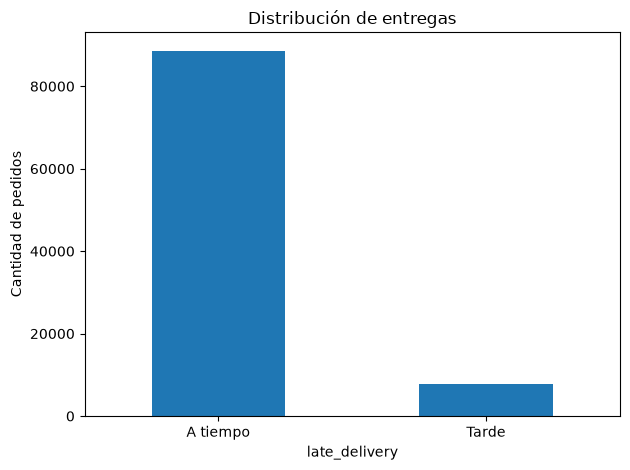

In [4]:
distribucion = gold["late_delivery"].value_counts().sort_index()
display(pd.DataFrame({"pedidos": distribucion, "porcentaje": (distribucion / len(gold) * 100).round(2)}))
ax = distribucion.rename(index={0:"A tiempo",1:"Tarde"}).plot.bar(title="Distribución de entregas", rot=0)
ax.set_ylabel("Cantidad de pedidos")
plt.tight_layout()
plt.show()


## 3. Variables predictoras y prevención de fuga temporal
El modelo usa variables de la orden, sus ítems, vendedor, cliente y ubicación. **No debe usar como predictor** `order_delivered_customer_date`, `late_delivery` ni otros datos conocidos después de la entrega. La fecha real de entrega se usa únicamente para construir la etiqueta histórica.

**Validación pendiente de negocio:** documentar que la fecha estimada, el precio, el envío y los atributos del pedido estaban disponibles en el momento exacto de confirmación. Los resultados se basan en pedidos históricos con etiqueta observable, no en pedidos activos.

In [6]:
columnas_excluidas = {"order_id", "order_purchase_timestamp", "late_delivery"}
variables_modelo = [c for c in gold.columns if c not in columnas_excluidas]
print("Variables candidatas para el modelo:")
for columna in variables_modelo:
    print("-", columna)
print("Variable objetivo:", "late_delivery")


Variables candidatas para el modelo:
- cantidad_items
- cantidad_vendedores
- valor_total
- freight_value
- peso_total_g
- volumen_total_cm3
- categoria_principal
- estado_origen
- estado_destino
- distancia_km
- mismo_estado
- dia_semana_compra
- mes_compra
- dias_estimados_entrega
Variable objetivo: late_delivery


### Validación de variables predictoras y prevención de fuga temporal

Se analizaron las 14 variables predictoras utilizadas en el modelo de clasificación del riesgo de entrega tardía, verificando su origen y su posible disponibilidad al momento de confirmar una orden.

No se utilizaron como predictores la fecha real de entrega ni la variable objetivo `late_delivery`, ya que ambas contienen información que solo se conoce posteriormente.

Las variables relacionadas con la cantidad de artículos, el valor de la compra, la ubicación del cliente y la fecha de compra se consideran disponibles, en principio, durante el proceso de confirmación.

Para otras variables, como el costo de envío, los atributos físicos del producto, la asignación del vendedor y la fecha estimada de entrega, se asume que estaban disponibles al confirmar la orden.

**Limitación:** el conjunto de datos OLIST no permite verificar el momento exacto en que se registró o actualizó cada atributo. Por lo tanto, no es posible garantizar completamente la ausencia de fuga temporal sin información adicional sobre el funcionamiento histórico del sistema.

Esta limitación debe considerarse antes de implementar el modelo en un entorno operativo real.

## 4. Entrenamiento y comparación de modelos
El archivo `modelo_clasificacion.py` contiene el procedimiento oficial del equipo: división **cronológica** entrenamiento/validación/prueba, preprocesamiento dentro de pipelines, `DummyClassifier` como baseline y comparación de regresión logística, Random Forest e HistGradientBoosting. La selección del modelo se hace mediante PR-AUC de validación; el umbral operativo se elige mediante F1 de validación.

La siguiente celda **ejecuta el script original completo**. Puede tardar y necesita SQL Server local, los CSV de Bronze y las dependencias del README. No se ejecuta automáticamente al abrir el notebook.

In [16]:
comparacion = pd.DataFrame({
    "Modelo": [
        "DummyClassifier (baseline)",
        "Regresión Logística",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "PR-AUC validación": [
        0.0810,
        0.2076,
        0.1781,
        0.1860
    ]
})

display(comparacion.sort_values(
    "PR-AUC validación", ascending=False
))

,Modelo,PR-AUC validación
1,Regresión Logística,0.2076
3,HistGradientBoosting,0.1860
2,Random Forest,0.1781
0,DummyClassifier (baseline),0.0810


In [7]:
# EJECUCIÓN OPCIONAL DEL PIPELINE COMPLETO (descomenta únicamente en tu computadora):
# import subprocess, sys
# resultado = subprocess.run([sys.executable, "modelo_clasificacion.py"],
#                            cwd=PROYECTO, capture_output=True, text=True, check=True)
# (PROYECTO / "resultados_modelo.txt").write_text(resultado.stdout, encoding="utf-8")
# print(resultado.stdout[-12000:])
print("Para volver a entrenar: descomenta la celda, confirma SQL Server y ejecútala.")


Para volver a entrenar: descomenta la celda, confirma SQL Server y ejecútala.


## 5. Evaluación y métricas
Se muestran los resultados históricos que generó el script del equipo, si existe `resultados_modelo.txt`. Los valores **no se recalculan aquí** sin volver a ejecutar el modelo. La matriz de confusión corresponde al conjunto temporal de prueba.

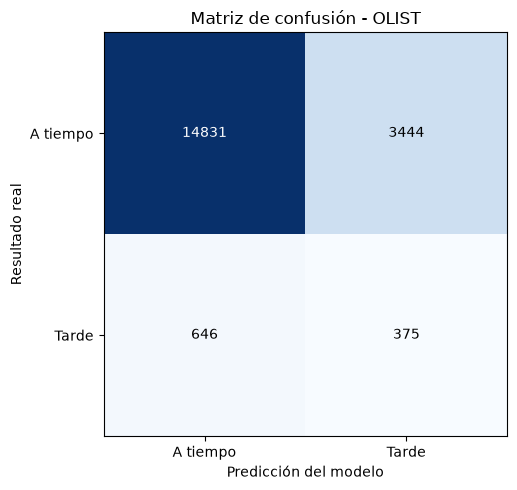

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Valores obtenidos de resultados_modelo.txt
matriz = np.array([
    [14831, 3444],
    [646, 375]
])

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(matriz, cmap="Blues")

ax.set_xticks([0, 1], ["A tiempo", "Tarde"])
ax.set_yticks([0, 1], ["A tiempo", "Tarde"])

ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Resultado real")
ax.set_title("Matriz de confusión - OLIST")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(matriz[i, j]),
            ha="center", va="center",
            color="white" if matriz[i, j] > 7000 else "black"
        )

plt.tight_layout()
plt.show()


## 6. Ranking de riesgo y propuesta de negocio
El ranking corresponde a **pedidos históricos del conjunto de prueba**; no representa órdenes activas. La revisión humana es una **recomendación operativa**, no una intervención que el equipo ya haya realizado.

In [15]:
ruta_ranking = PROYECTO / "outputs" / "pedidos_priorizados.csv"
if ruta_ranking.exists():
    ranking = pd.read_csv(ruta_ranking)
    print("Pedidos en ranking:", len(ranking))
    print("Columnas:", ranking.columns.tolist())
    display(ranking.head(10))
else:
    print("No se encontró el ranking. Ejecutar modelo_clasificacion.py para generarlo.")


Pedidos en ranking: 19296
Columnas: ['prioridad', 'order_id', 'order_purchase_timestamp', 'probabilidad_retraso', 'umbral_seleccionado', 'priorizar']


,prioridad,order_id,order_purchase_timestamp,probabilidad_retraso,umbral_seleccionado,priorizar
0,1,cf4659487be50c0c317cff3564c4a840,2018-07-02 16:39:59,0.999972,0.65,True
1,2,43bdbd9dc0931d72befdf4765af6c442,2018-07-06 11:07:02,0.966331,0.65,True
2,3,3fde74c28a3d5d618c00f26d51baafa0,2018-08-13 14:07:50,0.963580,0.65,True
3,4,076d1555fb53a89b0ef4d529e527a0f6,2018-07-30 10:04:21,0.959094,0.65,True
4,5,97415fb39aa90a8bfea4424d7bfbc5db,2018-08-19 14:08:32,0.952056,0.65,True
5,6,b72f2809724c9676ae9bc68a12d9626d,2018-08-19 21:21:03,0.951442,0.65,True
6,7,94fca82966c05ba707f4e7dc0c50aa3c,2018-08-15 17:00:49,0.949572,0.65,True
7,8,e7ad3898894027b09ce153449f7bc10d,2018-08-04 23:34:53,0.949542,0.65,True
8,9,fe1a4e86595ca403c258c586e8fd99c4,2018-08-17 01:04:15,0.947713,0.65,True
9,10,3e734ad65fdbca928a1a4de48d096ce4,2018-08-21 10:35:40,0.945987,0.65,True


## 7. Interpretación y limitaciones
- El modelo elegido fue **Regresión Logística**, seleccionado por PR-AUC de validación.
- El umbral operativo utilizado fue **0,65**, ajustado en validación.
- En la evaluación histórica reportada, **Precision ≈ 9,82 %**, **Recall ≈ 36,73 %**, **F1 ≈ 15,50 %** y **ROC-AUC ≈ 0,713**. Estas cifras deben cotejarse con `resultados_modelo.txt` si se reentrena.
- Existen **falsas alarmas** y atrasos no detectados. Por ello se propone que logística verifique los pedidos priorizados antes de actuar.
- Las probabilidades no están calibradas como riesgo real en producción; se requeriría validación adicional.
- Solo se entrenó con pedidos históricos cuya fecha real y estimada permiten determinar el resultado. Esto limita la generalización.
- Antes de desplegarlo, deben verificarse disponibilidad temporal de variables, estabilidad del modelo y capacidad operativa de revisión.

**Conclusión:** el proyecto demuestra un pipeline de ingeniería de datos y clasificación con evaluación temporal y propuesta preventiva; no demuestra que la operación logística ya haya reducido atrasos.


### Principales factores asociados a la predicción del riesgo de entrega tardía

El modelo final seleccionado fue **Regresión Logística**. Para interpretar sus predicciones se utilizó la técnica de importancia por permutación, aplicada a una muestra de 5.000 pedidos del conjunto de prueba, con tres repeticiones y utilizando PR-AUC como métrica.

Los cinco factores con mayor importancia predictiva fueron:

1. **Días estimados de entrega (`dias_estimados_entrega`): 0,05851.** Fue la variable más importante. Representa el tiempo previsto entre la compra y la fecha estimada de entrega. Su información contribuye significativamente a distinguir pedidos con riesgo de atraso.

2. **Estado de destino (`estado_destino`): 0,00369.** Representa la ubicación del cliente en Brasil. Su importancia indica que el destino aporta información útil para identificar patrones de riesgo logístico.

3. **Valor total (`valor_total`): 0,00363.** Corresponde al valor acumulado de los artículos comprados. El modelo utiliza esta característica como parte de la evaluación del riesgo.

4. **Cantidad de artículos (`cantidad_items`): 0,00333.** Representa el número de artículos incluidos en cada pedido. Aporta información sobre las características de las órdenes.

5. **Cantidad de vendedores (`cantidad_vendedores`): 0,00249.** Representa cuántos vendedores participan en una misma orden. Esta información también contribuye a la capacidad predictiva del modelo.

**Interpretación:** los valores corresponden a la reducción promedio de PR-AUC cuando se altera aleatoriamente cada variable. Cuanto mayor es la reducción, mayor es su importancia predictiva en esta evaluación.

Estos resultados no demuestran relaciones de causa y efecto ni permiten determinar, por sí solos, si un aumento en determinada variable incrementa o disminuye el riesgo.

**Aplicación empresarial:** los factores identificados pueden orientar la revisión de pedidos señalados por el modelo, especialmente considerando el plazo estimado de entrega, el destino y las características de cada orden. Las alertas deben servir como apoyo a la toma de decisiones y no como decisiones automáticas.

### Selección y justificación del umbral operativo

El modelo final de Regresión Logística utiliza un umbral de clasificación de **0,65**, seleccionado mediante la maximización de F1 en el conjunto de validación, evitando utilizar los resultados de prueba para elegirlo.

En la evaluación temporal de prueba, este umbral obtuvo una precisión de **9,82 %**, un recall de **36,73 %** y un F1 de **0,1550**. Se generaron 3.819 alertas, de las cuales 375 correspondieron a entregas tardías y 3.444 fueron falsas alarmas.

Como análisis comparativo, el umbral de 0,50 permitió detectar 834 entregas tardías, alcanzando un recall de 81,68 %, pero generó 9.500 alertas, incluyendo 8.666 falsas alarmas.

El umbral de 0,65 reduce considerablemente el volumen de alertas, pero también disminuye la capacidad de detectar atrasos. Por lo tanto, aunque su selección fue metodológicamente válida, **no puede considerarse un umbral operativo óptimo sin conocer la capacidad de revisión de pedidos y los costos asociados a las falsas alarmas y los atrasos no detectados**.

Se recomienda utilizar las predicciones como herramienta de priorización para revisión humana. Antes de una implementación real, la empresa debería establecer sus necesidades operativas y validar el umbral con datos posteriores.

## 8. Entregables relacionados
- `outputs/gold_order_delivery_risk_features.csv`: dataset analítico.
- `resultados_modelo.txt`: métricas y comparación de modelos.
- `outputs/pedidos_priorizados.csv`: lista histórica priorizada.
- `outputs/reporte_riesgo_entrega.html`: visualización y propuesta preventiva.
- `README.md`: pasos para ejecutar el proyecto.
- `modelo_clasificacion.py`: implementación reproducible del entrenamiento.

